# Step 2 - vAIRRify analysis: technical variation, labels and shortcuts

General repertoire properties such as V-gene usage and repertoire size can be shaped by biology, but also by various technical factors including primer efficiency, library prep and sequencing depth. 
When a batch lines up with a label such as disease, those technical differences give a downstream model a shortcut. 
This notebook follows the first part of the manuscript (Fig. 2, Table 1, Fig. 3) to find such **shortcut learning** opportunities for one label:

- What drives variation in the features: the batch, the label, or the covariates? (steps 7–9)
- Can a simple classifier on general repertoire features predict the label? (step 10)
- Does that signal hold within mixed-label batches, or does it vanish once the batch is fixed? (step 11)

**You choose the features once, in step 1.** QC, PCA, the variance analysis and the baseline classifier all use them. To compare features, e.g. V genes with depth, rerun the notebook with another choice.

Practically, we make use of the previously ingested data and its standardized format, and the `vairrify` package, which provides the key methods and plotting functions for each step of the analysis.

## 0. Setup and data loading

In [ ]:
from pathlib import Path
import numpy as np
import polars as pl
import seaborn as sns

import vairrify as vf # load the vairrify package

pl.Config.set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(60)

polars.config.Config

In [13]:
# specify the processed dataset from step 0
ingested_dir = Path("../data/processed")   # where 0_ingest_data wrote the datasets
dataset_name = "zaslavsky"
locus = "TRB"

output_dir = Path("../reports")            # where the tables are saved, at the end

## 1. Select features

The general repertoire properties described in the manuscript are available as per-repertoire tables. In this step, you decide which of these tables are used as features. These properties span a range between likely technical features (e.g. V gene frequencies) and likely biological blocks (e.g. inferred HLA), although exactly separating these repertoire-shaping factors is not the goal of this analysis. 

You can select a single or multiple blocks. With several blocks, each counts equally in QC, PCA and the variance analysis, however many features it has. A single feature (e.g. repertoire size) gets no PCA or PVCA.

In [10]:
vf.feature_blocks()

block,kind,source,description
str,str,str,str
"""V genes""","""technical""","""GeneCountsSummary""","""share of clonotypes using each V gene"""
"""J genes""","""technical""","""GeneCountsSummary""","""share of clonotypes using each J gene"""
"""VJ bias""","""technical""","""GeneCountsSummary""","""log ratio of each V-J pairing to what independent V and J us…"
"""VDJ stats""","""technical""","""VdjStatisticsSummary""","""mean, sd, skew and kurtosis of trimming, P and N nucleotides"""
"""repertoire size""","""technical""","""repertoire counts""","""number of unique clonotypes"""
"""depth""","""technical""","""RarefactionReport""","""reads, and expected unique clonotypes at 20k / 48k / 200k / …"
"""HLA""","""biological""","""RepertoireHlaInference""","""inferred HLA carriage (score > 0.5)"""


In [15]:
features = ["V genes"]   # e.g. ["depth"], ["HLA"], or Table 1's ["V genes", "J genes", "VJ bias", "VDJ stats", "repertoire size"]

Loading reads the metadata, the depth and the feature blocks; a block that isn't computed yet is computed now. Two metadata columns are added: `log10_clonotypes` (depth, to use as a technical variable if you want) and `random_control` (three random groups, a negative control).

In [17]:
reps = vf.load(ingested_dir / dataset_name, locus=locus, features=features)

zaslavsky TRB: 593 repertoires, 542 with V genes (47 features), 12 metadata columns


## 2. Inspect the metadata

In this step, you can decide which 
Every metadata column, with its **kind**: numbers are continuous, everything else categorical. A column that `varies within patient` is a repertoire-level variable, such as timepoint.

In [18]:
reps.overview()

column,kind,dtype,distinct,nulls,examples,varies within patient
str,str,str,i64,i64,str,bool
"""repertoire_id""","""categorical""","""String""",593,0,"""BFI-0000234, BFI-0000254, BFI-0000255, BFI-0000256""",false
"""patient_id""","""categorical""","""String""",593,0,"""BFI-0000234, BFI-0000254, BFI-0000255, BFI-0000256""",null
"""study_name""","""categorical""","""String""",13,0,"""HIV, Healthy-StanfordBloodCenter, Healthy-StanfordBloodCente…",false
"""disease""","""categorical""","""String""",6,0,"""Healthy/Background, HIV, Lupus, Covid19""",false
"""disease_subtype""","""categorical""","""String""",28,0,"""Healthy/Background - HIV Negative, HIV Broad Neutralizing, H…",false
…,…,…,…,…,…,…
"""age""","""continuous""","""Int64""",78,41,"""27, 48, 33, 31""",false
"""sex""","""categorical""","""String""",2,98,"""M, F""",false
"""ancestry""","""categorical""","""String""",4,188,"""African, Caucasian, Asian, Hispanic/Latino""",false


### Metadata edits or clean-up (optional)

`with_metadata` takes polars expressions, as `with_columns`. Cast a column to change its kind. Leave the cell as is if nothing needs changing.

In [20]:
# reps = reps.with_metadata(pl.col("sex").replace({"F": "female", "M": "male"}))
# reps = reps.with_metadata(experiment=pl.col("run_id").str.split("/").list.first())   # a level above the batch
# reps = reps.with_metadata(pl.col("cv_fold").cast(pl.String))                         # an integer-coded grouping

## 3. QC: repertoires that shouldn't be analysed

A few failed libraries can dominate everything downstream. Each repertoire is checked for **low depth** (fewer than `min_clonotypes`), **missing genes** (more than `max_zero` genes never observed, in gene-usage blocks) and an **atypical profile** (distance to the typical profile more than `outlier_iqr` IQRs above the upper quartile).

The first two are failures. An atypical profile is only a reason to look: it can be biology, and so can low depth (e.g. lymphopenia).

0 failed, 9 atypical


repertoire_id,clonotypes,genes at zero,distance,flags
str,f64,i64,f64,str
"""BFI-0009080""",15041.0,2,4.323026,"""atypical profile"""
"""BFI-0009121""",14987.0,3,4.1763,"""atypical profile"""
"""BFI-0009144""",11859.0,4,3.887158,"""atypical profile"""
"""BFI-0009122""",26474.0,3,3.477598,"""atypical profile"""
"""BFI-0009048""",47421.0,2,3.385721,"""atypical profile"""
"""BFI-0003143""",6431.0,5,2.583993,"""atypical profile"""
"""BFI-0003052""",6155.0,5,2.389972,"""atypical profile"""
"""BFI-0009154""",39182.0,3,2.316936,"""atypical profile"""
"""BFI-0003738""",28423.0,3,2.233301,"""atypical profile"""


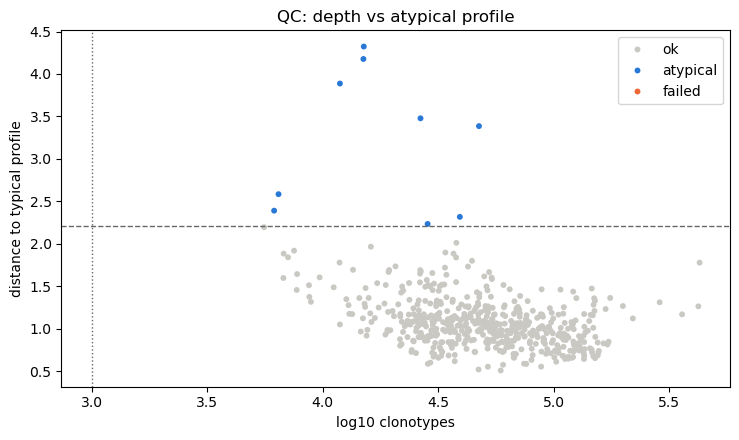

In [21]:
# ⚙ settings: qc
qc = reps.qc(min_clonotypes=1000, max_zero=10, outlier_iqr=3)
print(f"{len(qc.failed)} failed, {len(qc.atypical)} atypical")
vf.plots.qc(qc)
qc.table.filter(pl.col("flags") != "")

## 4. Design - assign variables and covariates

The variables are the manuscript's **repertoire-shaping factors** (Fig. 1): technical factors, the label (disease status), biological covariates, and controls. Each variable gets one role; its kind is the one in step 2. One design looks at one label: for a second label, make a second design.

| Role | What it is | Example |
|---|---|---|
| `label` | what a downstream model would be trained to predict (categorical) | disease, serostatus |
| `batch` | the main technical grouping, used for the within-batch evaluation | library prep, run, study |
| `other_technical` | further technical factors, e.g. depth (`log10_clonotypes`) | experiment, depth |
| `covariates` | biological factors that may shape the repertoire | age, sex, ancestry |
| `controls` | should explain nothing, e.g. a computational split or a CV fold. `random_control` is always added. | fold, split |

**Samples.** A repertoire is analysed when it has every feature, a label and a batch, and was not excluded (`exclude`, e.g. `qc.failed` or `qc.flagged`). A patient's repertoires all stay: the baseline classifier's random folds keep them together, but PERMANOVA's permutations treat them as independent. PCA and variance also drop repertoires missing a continuous variable. Missing covariates become an `"unknown"` level (`covariate_missing="level"`) or drop the repertoire (`"drop"`). Covariate and control levels with fewer than `min_level_size` repertoires merge into `"other"`.

In [ ]:
design = reps.design(
    label="disease",                       # what a downstream model would be trained to predict
    batch="study_name",                    # main technical grouping; None if there is only one
    other_technical=[],
    covariates=["age", "sex", "ancestry"], # further known biological factors that may explain variation in the data
    controls=[],                           # factors that likely do not explain variation in the data, but may be useful to include in a model
    exclude=qc.failed,                     # samples to exclude from the design, e.g. low repertoire counts or contaminated samples
    covariate_missing="level",             # "level" or "drop" - if "level", missing values are treated as a separate level of the covariate; if "drop", samples with missing values are dropped from the design
)
design.summary()

variable,role,kind,distinct,nulls,PVCA
str,str,str,i64,i64,str
"""study_name""","""technical""","""categorical""",13,0,"""as is"""
"""disease""","""label""","""categorical""",6,0,"""as is"""
"""age""","""covariate""","""continuous""",78,41,"""binned"""
"""sex""","""covariate""","""categorical""",2,98,"""as is"""
"""ancestry""","""covariate""","""categorical""",4,188,"""as is"""
"""random_control""","""control""","""categorical""",3,0,"""as is"""


In [23]:
design.samples()

step,repertoires
str,i64
"""all repertoires""",593
"""with TRB data for every feature""",542
"""not excluded by QC""",542
"""analysed: has 'disease' and 'study_name'""",542
""" of which patients""",542
"""PCA / variance: no missing continuous values""",504


## 5. Is the label balanced over batches? (Fig. S1)

Repertoires per batch and label level, and how tied label and batch are (bias-corrected Cramér's V): **balanced** (V < 0.1), a model gains little from recognising the batch; **imbalanced** (0.1–0.5), a shortcut is possible; **confounded** (V ≥ 0.5), batch and label largely coincide and the features can't separate them.

Only **mixed-label batches**, holding more than one label level, allow a within-batch evaluation (step 11). Single-label batches are marked in the heatmap.

study_name,Covid19,HIV,Healthy/Background,Influenza,Lupus,T1D,batch type
str,u32,u32,u32,u32,u32,u32,str
"""Diabetes biobank""",0,0,3,0,0,92,"""mixed-label"""
"""HIV""",0,95,43,0,0,0,"""mixed-label"""
"""New Lupus Paxgene""",0,0,2,0,5,0,"""mixed-label"""
"""New Lupus RNA""",0,0,4,0,15,0,"""mixed-label"""
"""Covid19-Stanford""",48,0,0,0,0,0,"""single-label"""
…,…,…,…,…,…,…,…
"""Flu vaccine UPenn 2021""",0,0,0,37,0,0,"""single-label"""
"""Healthy-StanfordBloodCenter""",0,0,72,0,0,0,"""single-label"""
"""Healthy-StanfordBloodCenter_included-in-resequencing""",0,0,30,0,0,0,"""single-label"""


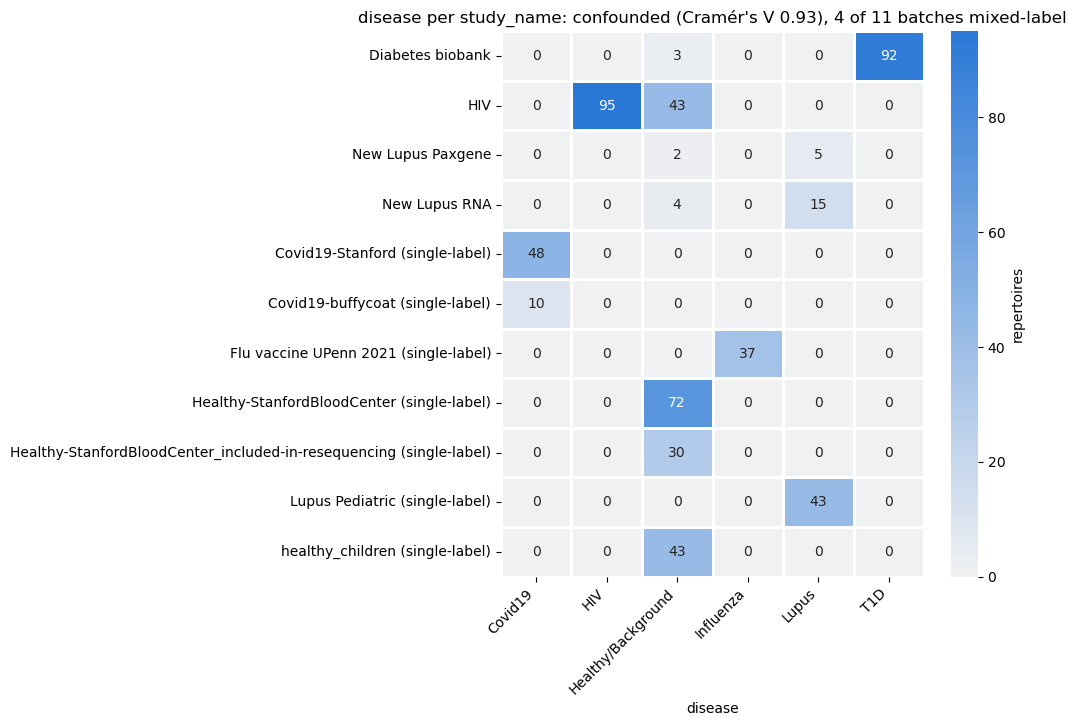

In [29]:
balance = design.balance()
fig = vf.plots.balance(balance)
ax = fig.axes[0]
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
balance

## 6. PCA (Fig. 2B)

The leading `n_components` components of the features (for gene usage: log1p counts, L2-normalised, then scaled). The plots show two of them, `x` and `y`, coloured by the label, next to the features that load most on those two. V genes whose usage varies between people for germline reasons (`vf.features.GERMLINE_V_GENES`: deletion polymorphisms and linked alleles), so that their variation needn't be technical, are marked in orange. The second figure has one panel per batch. Batches forming their own clusters means batch drives the features.

explained variance: PC1 24%, PC2 14%, PC3 10%, PC4 6%, PC5 5%, PC6 4%, PC7 4%, PC8 3%, PC9 3%, PC10 2%


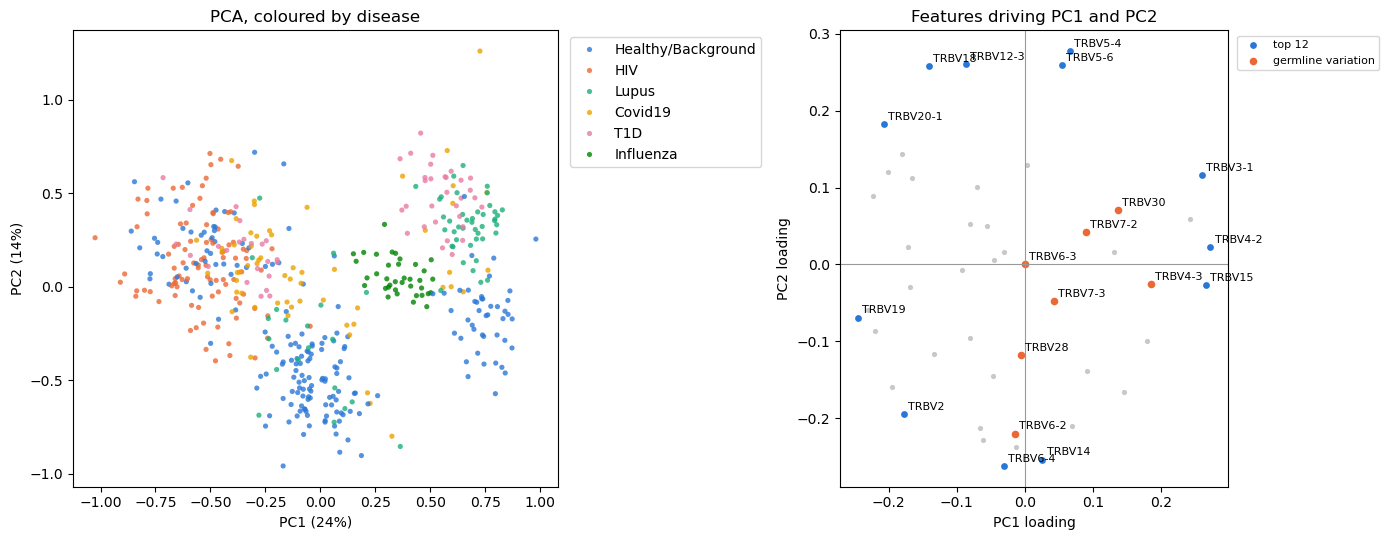

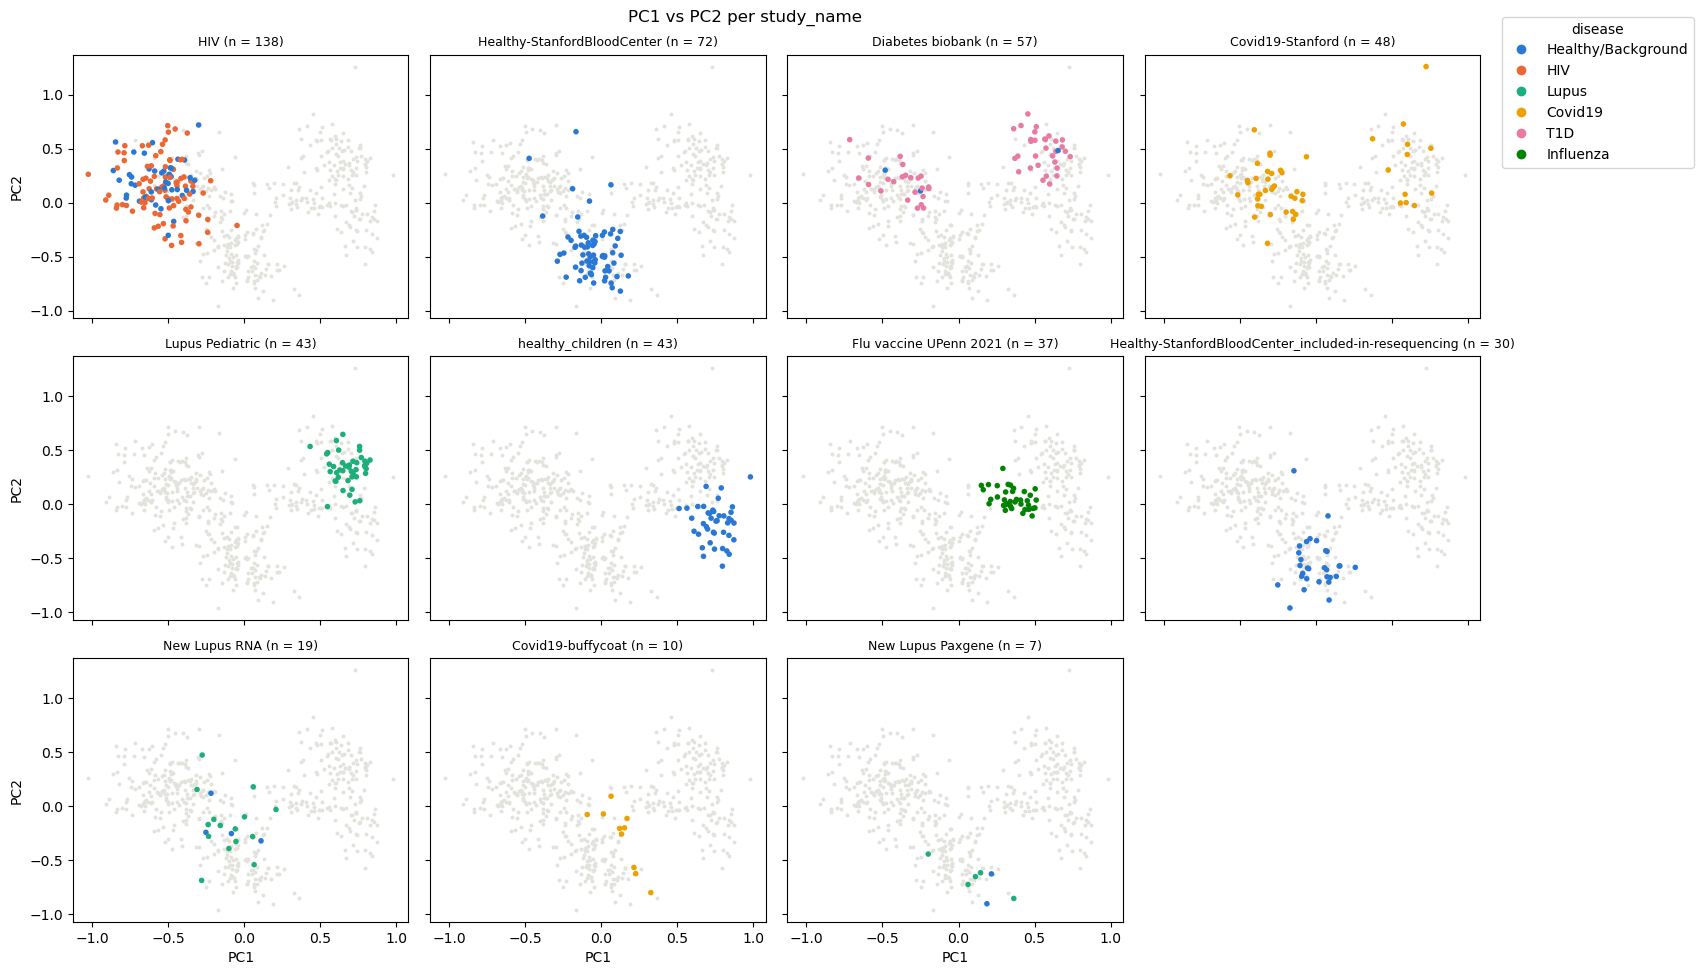

In [30]:
# ⚙ settings: pca
pca = design.pca(n_components=10)
x, y = "PC1", "PC2"                       # the components to plot
print("explained variance:", ", ".join(f"PC{i + 1} {e:.0%}" for i, e in enumerate(pca.explained)))
vf.plots.pca(pca, x=x, y=y)
vf.plots.pca_by_batch(pca, x=x, y=y);

## 7. Sources of variation (Fig. 2A)

- **PVCA** (left) splits variance into components, averaged over the leading PCs. Continuous variables are binned: with the edges in `pvca_bins`, otherwise into `pvca_n_bins` equal-sized groups.
- **PERMANOVA** (right) gives each variable's share of the total variation **alone** and **adjusted** for all others. A label that is large alone but small adjusted shows up mainly through what it is tied to, usually the batch. Controls should sit near zero.

With depth features (repertoire size, depth), adding `log10_clonotypes` as a variable is circular: it measures the same thing as the features.

variable,role,kind,PVCA share,R² alone,R² adjusted,p adjusted
str,str,str,f64,f64,f64,f64
"""study_name""","""technical""","""categorical""",0.634622,0.388651,0.118172,0.001
"""disease""","""label""","""categorical""",0.012421,0.211922,0.006478,0.013
"""ancestry""","""covariate""","""categorical""",0.003231,0.160782,0.015599,0.001
"""age""","""covariate""","""continuous""",0.002453,0.050086,0.003099,0.01
"""sex""","""covariate""","""categorical""",0.000006,0.031089,0.001307,0.332
"""random_control""","""control""","""categorical""",0.000401,0.003469,0.002933,0.202


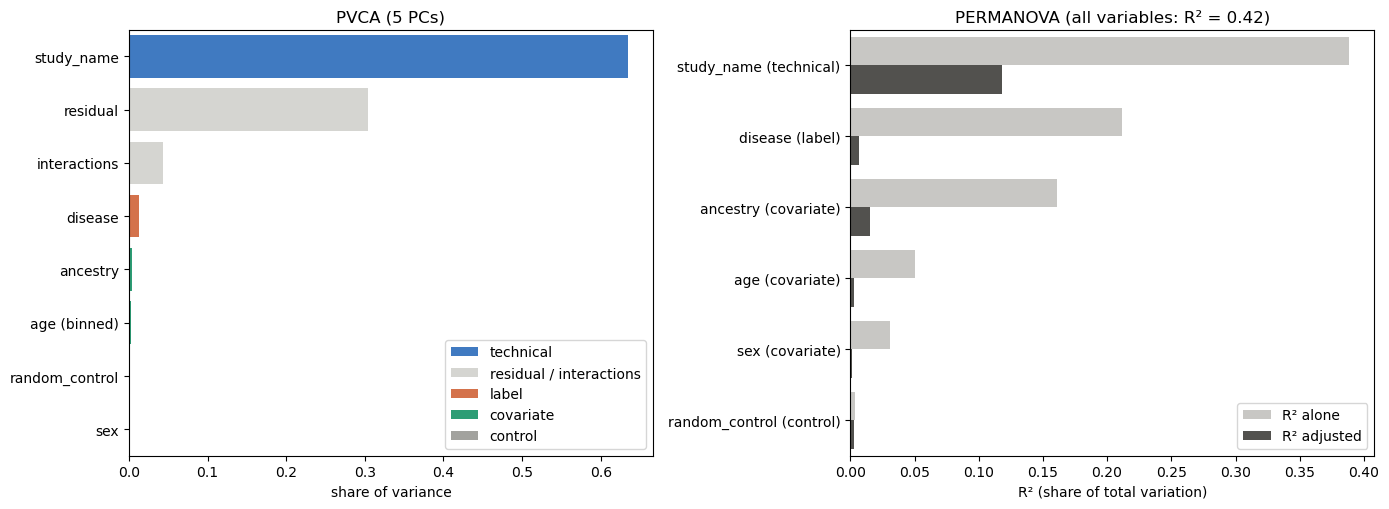

In [31]:
# ⚙ settings: variance
var = design.variance(permutations=999, pvca_bins={"age": [0, 10, 20, 30, 40, 50, 60, 70, np.inf]})   # decades, as in the manuscript
vf.plots.variance(var)
var

## 10. Baseline classifier: can the features predict the label? (Table 1, Fig. 3A)

A random forest predicts each label class against the rest, scored out of fold. With `cv_column` the folds are the downstream model's own, so this shows what *that* model could exploit. Without it, 3 random folds keep patients together, are stratified on batch × label, and are repeated `cv_repeats` times. The batch (positive control) and the controls (should sit at 0.5) are predicted too.

variable,role,class,n,positives,auc,ap
str,str,str,i64,i64,f64,f64
"""disease""","""label""","""Influenza""",542,37,1.0,1.0
"""disease""","""label""","""T1D""",542,92,0.982,0.928
"""disease""","""label""","""Healthy/Background""",542,197,0.961,0.953
"""disease""","""label""","""HIV""",542,95,0.961,0.768
"""disease""","""label""","""Covid19""",542,58,0.956,0.749
…,…,…,…,…,…,…
"""study_name""","""technical""","""Healthy-StanfordBloodCenter""",542,72,0.952,0.601
"""study_name""","""technical""","""Healthy-StanfordBloodCenter_included-in-resequencing""",542,30,0.938,0.318
"""random_control""","""control""","""r2""",542,171,0.495,0.304


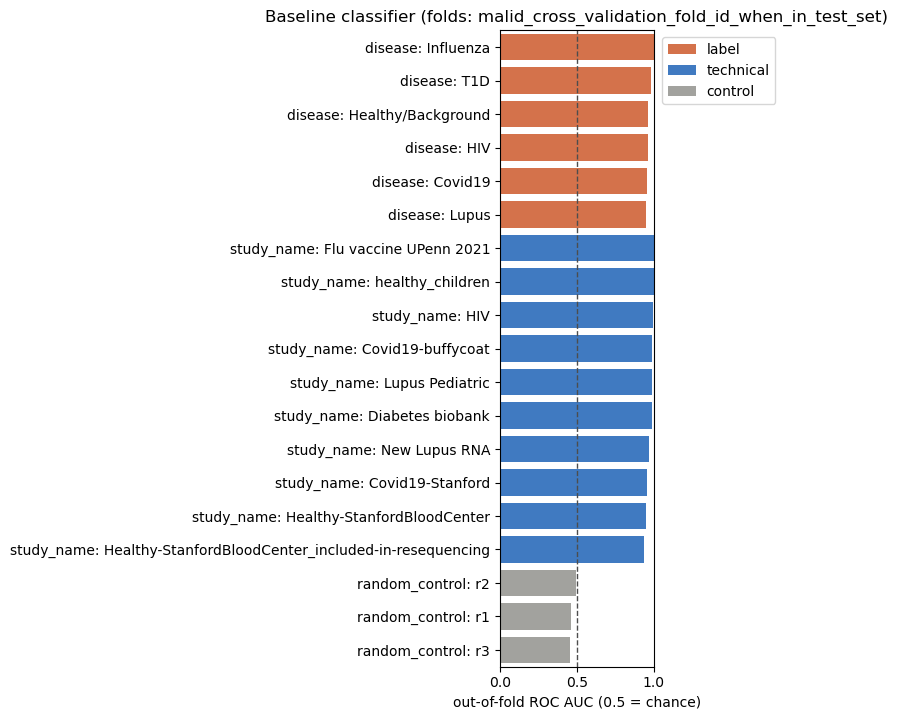

In [32]:
# ⚙ settings: baseline classifier
base = design.baseline(cv_column="malid_cross_validation_fold_id_when_in_test_set",   # the downstream model's folds
                       min_class_size=10, cv_repeats=3)
vf.plots.baseline(base)
base.table.with_columns(pl.col(pl.Float64).round(3))

## 8. Within-batch evaluation: does it hold once the batch is fixed?

The manuscript's within-batch evaluation, applied to the baseline classifier. For each label class: **all batches**, the AUC from step 10, next to **within batch**, the same out-of-fold scores judged inside the mixed-label batches that hold at least `min_group_class_size` of both the class and the rest. A high AUC across batches that drops within batches points to a batch shortcut. Blank cells could not be tested: no batch holds both.

class,all batches,within batch,mixed-label batches,batches with class
str,f64,f64,i64,i64
"""Covid19""",0.96,null,0,2
"""HIV""",0.96,0.65,1,1
"""Healthy/Background""",0.96,0.87,1,7
"""Influenza""",1.0,null,0,1
"""Lupus""",0.95,null,0,3
"""T1D""",0.98,null,0,1


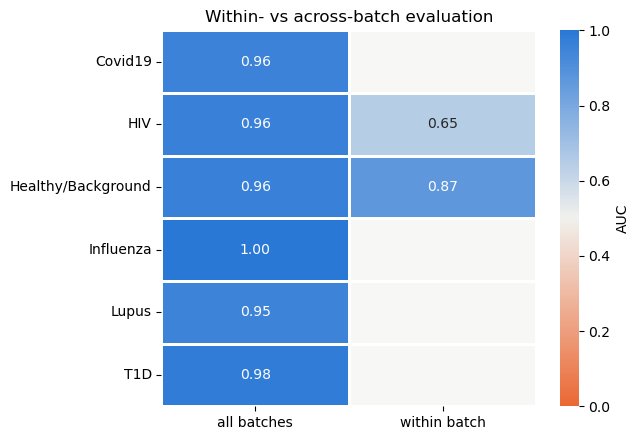

In [34]:
within = design.within_batch(base, min_group_class_size=5)   # both classes need this many repertoires in a batch
vf.plots.within_batch(within)
within.with_columns(pl.col(pl.Float64).round(2))

## 9. Interpretability: driving features of the baseline model

**Which features carry it?** (Fig. 3B) Mean |SHAP| over out-of-fold repertoires, for `target` (a label class), by default the most recoverable class. Pink bars: positively associated with the class, a higher value pushes towards it; blue: negatively associated (the sign of the correlation between a feature's value and its SHAP value). Features that also load on the PCs in step 8 point to batch.

feature,mean_abs_shap,value-SHAP correlation,association
str,f64,f64,str
"""TRBV3-1""",0.03987,0.461118,"""positive"""
"""TRBV18""",0.032482,0.786591,"""positive"""
"""TRBV15""",0.026863,-0.292221,"""negative"""
"""TRBV4-2""",0.024544,0.107626,"""positive"""
"""TRBV5-4""",0.024462,0.737297,"""positive"""
…,…,…,…
"""TRBV27""",0.018857,-0.594839,"""negative"""
"""TRBV2""",0.017626,-0.762832,"""negative"""
"""TRBV7-8""",0.016749,0.727169,"""positive"""


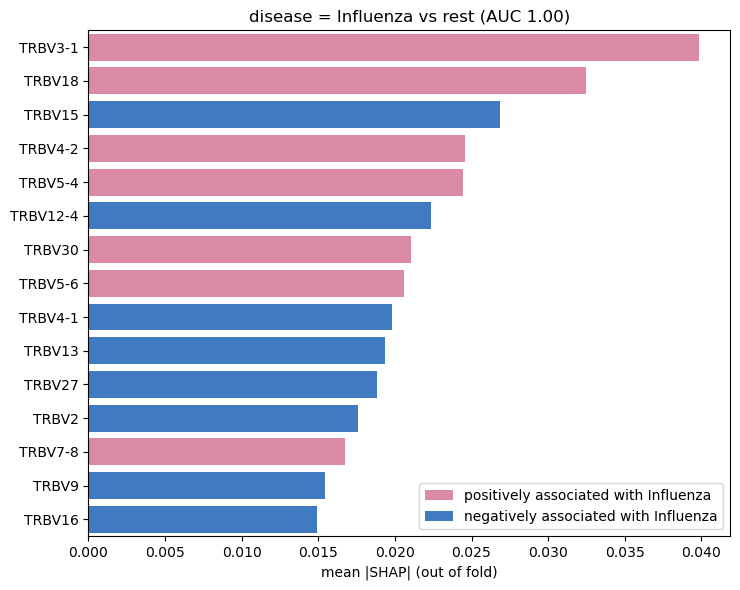

In [35]:
# ⚙ settings: shap
shap = design.shap(base, target=None)
vf.plots.shap(shap)
shap

Save every table as TSV.

In [36]:
vf.save(output_dir / dataset_name / locus / design.label / " + ".join(features), qc=qc, samples=design.samples(),
        balance=balance, pca_loadings=pca, variance=var, baseline=base, within_batch=within, shap=shap)

[PosixPath('../reports/zaslavsky/TRB/disease/V genes/qc.tsv'),
 PosixPath('../reports/zaslavsky/TRB/disease/V genes/samples.tsv'),
 PosixPath('../reports/zaslavsky/TRB/disease/V genes/balance.tsv'),
 PosixPath('../reports/zaslavsky/TRB/disease/V genes/pca_loadings.tsv'),
 PosixPath('../reports/zaslavsky/TRB/disease/V genes/variance.tsv'),
 PosixPath('../reports/zaslavsky/TRB/disease/V genes/baseline.tsv'),
 PosixPath('../reports/zaslavsky/TRB/disease/V genes/within_batch.tsv'),
 PosixPath('../reports/zaslavsky/TRB/disease/V genes/shap.tsv')]